# INGV Volcanic : Basic_solution (STFT)
**Volcanic earthquakes** have various characteristics depending on the volcano, and there are various classifications, but the typical classifications can be classified as follows.
 
**Volcanic earthquake**
 * type A (10Hz or higher): Earthquake caused by destruction of rocks surrounding magma chambers and conduits
 * type BH (5-8Hz) : Earthquake caused by magma intruding into the conduit and destroying the conduit and rocks around the conduit
 * type BL (1.5-2.5Hz) : An earthquake around the conduit due to gas etc. ejecting from the crater prior to the explosive eruption and reducing the pressure inside the conduit.

**Volcanic tremor**
 * type C (0.5-1.2Hz) : Vibration due to increase in gas pressure in the cavity along with BH
 * type D (2-4Hz) : Vibration due to gas ejection along with BL
 

In [1]:
import os
import datetime
from tqdm.notebook import tqdm

import numpy as np
import pandas as pd
import scipy
import scipy.signal

import matplotlib
import matplotlib.pyplot as plt
pd.options.display.max_columns = None    # disp all columns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error as mse

# from lightgbm import LGBMRegressor
import lightgbm as lgb

In [2]:
### Kaggle or Local-PC ###
KAGGLE = True       # <==== SET ============

if KAGGLE:
    DIR = '../input/predict-volcanic-eruptions-ingv-oe'
else:              # local PC
    DIR = './predict-volcanic-eruptions-ingv-oe/'

# Data

In [3]:
train = pd.read_csv(os.path.join(DIR, 'train.csv'))
test = pd.read_csv(os.path.join(DIR, 'sample_submission.csv'))

train

,segment_id,time_to_eruption
0,1136037770,12262005
1,1969647810,32739612
2,1895879680,14965999
3,2068207140,26469720
4,192955606,31072429
...,...,...
4426,873340274,15695097
4427,1297437712,35659379
4428,694853998,31206935
4429,1886987043,9598270


In [4]:
# Convert 'time_to_eruption'to hours:minutes:seconds (Just for reference)
train['h:m:s'] = (train['time_to_eruption']
                  .apply(lambda x:datetime.timedelta(seconds = x/100)))
train

,segment_id,time_to_eruption,h:m:s
0,1136037770,12262005,1 days 10:03:40.050000
1,1969647810,32739612,3 days 18:56:36.120000
2,1895879680,14965999,1 days 17:34:19.990000
3,2068207140,26469720,3 days 01:31:37.200000
4,192955606,31072429,3 days 14:18:44.290000
...,...,...,...
4426,873340274,15695097,1 days 19:35:50.970000
4427,1297437712,35659379,4 days 03:03:13.790000
4428,694853998,31206935,3 days 14:41:09.350000
4429,1886987043,9598270,1 days 02:39:42.700000


# Observe sample data

In [5]:
# plot utility function
def plot(ax, x, y, xlabel=None, ylabel=None, legend=None):
    ax.plot(x, y, label = legend)
    if xlabel != None:
        ax.set_xlabel(xlabel)
    if ylabel != None:
        ax.set_ylabel(ylabel)
    if legend != None:
        ax.legend()
    ax.grid(True)

In [6]:
# Select sample segment
sample_df = (train.sort_values('time_to_eruption')
             .reset_index()
             .rename(columns={'index': 'train_id'}))
sample_df = sample_df[sample_df.index % (len(train) // 5) == 5].reset_index(drop = True)
sample_ids = sample_df['segment_id'].values
sample_df

,train_id,segment_id,time_to_eruption,h:m:s
0,3942,775594946,52074,0 days 00:08:40.740000
1,636,2078096366,8991164,1 days 00:58:31.640000
2,4059,522506128,17972903,2 days 01:55:29.030000
3,3851,100610446,27292311,3 days 03:48:43.110000
4,2787,1003411703,36831703,4 days 06:18:37.030000


### Time Domain

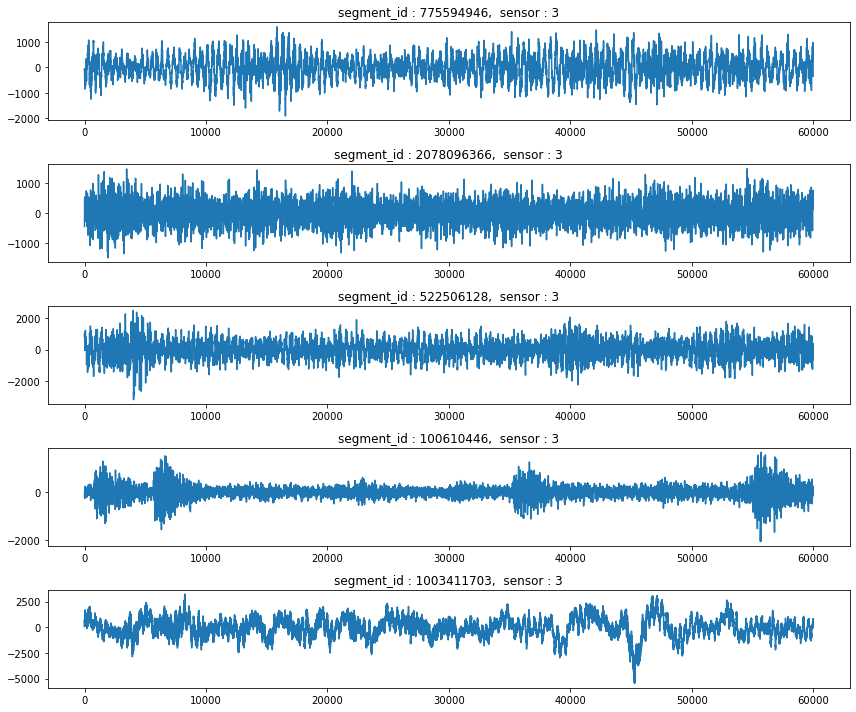

In [7]:
sensor = 3     #### 1 ～ 10

fig, ax = plt.subplots(len(sample_ids), 1, figsize = (12, len(sample_ids)*2))
for i, segment_id in enumerate(sample_ids):
    segment_df = pd.read_csv(os.path.join(DIR, f'train/{segment_id}.csv')).fillna(0)
    ax[i].plot(range(len(segment_df)), segment_df[f'sensor_{sensor}'])
    ax[i].set_title(f'segment_id : {segment_id},  sensor : {sensor}')

fig.tight_layout()

### Time-Frequency Domain (STFT)
STFT : Short Time Fourier Transform

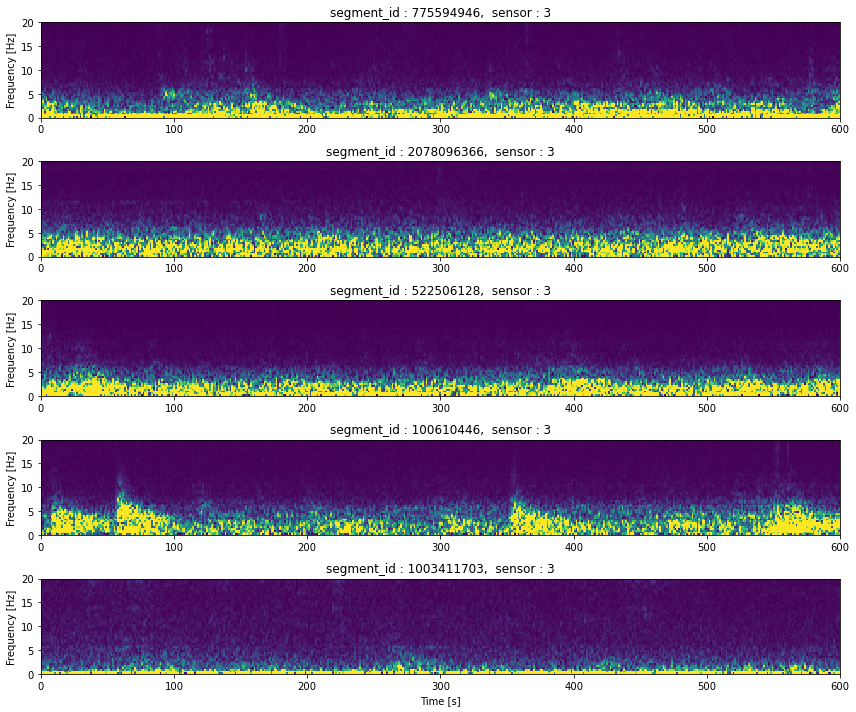

In [8]:
fs = 100                # sampling frequency 
N = len(segment_df)     # data size
n = 256                 # FFT segment size

fig, ax = plt.subplots(len(sample_ids), 1, figsize = (12, len(sample_ids)*2))
for i, segment_id in enumerate(sample_ids):
    segment_df = pd.read_csv(os.path.join(DIR, f'train/{segment_id}.csv')).fillna(0)
    
    x = segment_df[f'sensor_{sensor}'][:N]
    f, t, Z = scipy.signal.stft(x, fs = fs, window = 'hann', nperseg = n)
    Z = np.abs(Z)

    ax[i].pcolormesh(t, f, Z, vmin = 0, vmax = Z.mean()*10)
    ax[i].set_ylim(0, 20)
    ax[i].set_ylabel('Frequency [Hz]'); plt.xlabel('Time [s]')
    ax[i].set_title(f'segment_id : {segment_id},  sensor : {sensor}')
fig.tight_layout()

# Features

In [9]:
# STFT(Short Time Fourier Transform) Specifications
fs = 100                # sampling frequency 
N = len(segment_df)     # data size
n = 256                 # FFT segment size
max_f = 20              # ～20Hz

delta_f = fs / n        # 0.39Hz
delta_t = n / fs / 2    # 1.28s

In [10]:
def make_features(tgt):
    tgt_df = train if tgt == 'train' else test
    feature_set = []
    for segment_id in tqdm(tgt_df['segment_id']):
        segment_df = pd.read_csv(os.path.join(DIR,f'{tgt}/{segment_id}.csv'))
        segment = [segment_id]
        for sensor in segment_df.columns:
            x = segment_df[sensor][:N]
            if x.isna().sum() > 1000:     ##########
                segment += ([np.NaN] * 10)
                continue
            f, t, Z = scipy.signal.stft(x.fillna(0), fs = fs, window = 'hann', nperseg = n)
            f = f[:round(max_f/delta_f)+1]
            Z = np.abs(Z[:round(max_f/delta_f)+1]).T    # ～max_f, row:time,col:freq

            th = Z.mean() * 1     ##########
            Z_pow = Z.copy()
            Z_pow[Z < th] = 0
            Z_num = Z_pow.copy()
            Z_num[Z >= th] = 1

            Z_pow_sum = Z_pow.sum(axis = 0)
            Z_num_sum = Z_num.sum(axis = 0)

            A_pow = Z_pow_sum[round(10/delta_f):].sum()
            A_num = Z_num_sum[round(10/delta_f):].sum()
            BH_pow = Z_pow_sum[round(5/delta_f):round(8/delta_f)].sum()
            BH_num = Z_num_sum[round(5/delta_f):round(8/delta_f)].sum()
            BL_pow = Z_pow_sum[round(1.5/delta_f):round(2.5/delta_f)].sum()
            BL_num = Z_num_sum[round(1.5/delta_f):round(2.5/delta_f)].sum()
            C_pow = Z_pow_sum[round(0.6/delta_f):round(1.2/delta_f)].sum()
            C_num = Z_num_sum[round(0.6/delta_f):round(1.2/delta_f)].sum()
            D_pow = Z_pow_sum[round(2/delta_f):round(4/delta_f)].sum()
            D_num = Z_num_sum[round(2/delta_f):round(4/delta_f)].sum()
            segment += [A_pow, A_num, BH_pow, BH_num, BL_pow, BL_num, C_pow, C_num, D_pow, D_num]

        feature_set.append(segment)

    cols = ['segment_id']
    for i in range(10):
        for j in ['A_pow', 'A_num','BH_pow', 'BH_num','BL_pow', 'BL_num','C_pow', 'C_num','D_pow', 'D_num']:
            cols += [f's{i+1}_{j}']
    feature_df = pd.DataFrame(feature_set, columns = cols)
    feature_df['segment_id'] = feature_df['segment_id'].astype('int')
    return feature_df

In [11]:
feature_df = make_features('train')
train_set = pd.merge(train, feature_df, on = 'segment_id')
train_set

,segment_id,time_to_eruption,h:m:s,s1_A_pow,s1_A_num,s1_BH_pow,s1_BH_num,s1_BL_pow,s1_BL_num,s1_C_pow,s1_C_num,s1_D_pow,s1_D_num,s2_A_pow,s2_A_num,s2_BH_pow,s2_BH_num,s2_BL_pow,s2_BL_num,s2_C_pow,s2_C_num,s2_D_pow,s2_D_num,s3_A_pow,s3_A_num,s3_BH_pow,s3_BH_num,s3_BL_pow,s3_BL_num,s3_C_pow,s3_C_num,s3_D_pow,s3_D_num,s4_A_pow,s4_A_num,s4_BH_pow,s4_BH_num,s4_BL_pow,s4_BL_num,s4_C_pow,s4_C_num,s4_D_pow,s4_D_num,s5_A_pow,s5_A_num,s5_BH_pow,s5_BH_num,s5_BL_pow,s5_BL_num,s5_C_pow,s5_C_num,s5_D_pow,s5_D_num,s6_A_pow,s6_A_num,s6_BH_pow,s6_BH_num,s6_BL_pow,s6_BL_num,s6_C_pow,s6_C_num,s6_D_pow,s6_D_num,s7_A_pow,s7_A_num,s7_BH_pow,s7_BH_num,s7_BL_pow,s7_BL_num,s7_C_pow,s7_C_num,s7_D_pow,s7_D_num,s8_A_pow,s8_A_num,s8_BH_pow,s8_BH_num,s8_BL_pow,s8_BL_num,s8_C_pow,s8_C_num,s8_D_pow,s8_D_num,s9_A_pow,s9_A_num,s9_BH_pow,s9_BH_num,s9_BL_pow,s9_BL_num,s9_C_pow,s9_C_num,s9_D_pow,s9_D_num,s10_A_pow,s10_A_num,s10_BH_pow,s10_BH_num,s10_BL_pow,s10_BL_num,s10_C_pow,s10_C_num,s10_D_pow,s10_D_num
0,1136037770,12262005,1 days 10:03:40.050000,0.000000,0.0,5630.045792,271.0,46725.413729,841.0,37140.925547,452.0,72426.032531,1848.0,30798.673301,421.0,331692.549021,2631.0,45379.763380,468.0,22777.932701,225.0,206242.474535,1657.0,16604.279572,522.0,47417.802709,1311.0,40676.075383,769.0,33720.229669,437.0,80642.155584,1777.0,8226.754250,220.0,182647.140506,2530.0,35439.620873,582.0,24749.721001,356.0,103910.182217,1651.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9850.349498,214.0,16342.737759,354.0,36798.893833,596.0,77124.060729,455.0,66246.422330,1193.0,64934.954957,1035.0,102382.207522,1654.0,9591.874414,200.0,54211.464091,436.0,54659.345814,936.0,55699.430380,871.0,171324.956616,2096.0,7302.118775,131.0,52497.482994,420.0,56240.599886,850.0,40650.624075,635.0,83811.917208,1731.0,48613.305829,738.0,27587.750677,383.0,136269.764337,1950.0,2120.558313,43.0,81355.190778,1444.0,84886.270473,807.0,60996.871589,442.0,157529.563619,1825.0
1,1969647810,32739612,3 days 18:56:36.120000,0.000000,0.0,8239.546856,261.0,96756.954746,905.0,66797.019816,459.0,155685.002604,2091.0,28311.404222,394.0,236875.196678,2186.0,73926.011019,686.0,62508.203810,410.0,236954.067044,1889.0,0.000000,0.0,21212.917778,680.0,71868.730548,890.0,53765.696758,456.0,138627.821898,2102.0,0.000000,0.0,69588.814054,1538.0,71812.521656,866.0,49043.632001,446.0,135523.407364,2033.0,15991.156821,519.0,97574.156730,2131.0,37620.555312,702.0,14755.819719,322.0,109499.370581,1891.0,11990.687424,499.0,3199.959299,134.0,28420.061216,690.0,49615.324005,457.0,18742.696073,654.0,10419.983969,251.0,331.805383,9.0,35505.323034,723.0,90047.526424,462.0,25576.660444,762.0,11512.524601,362.0,44068.650240,1417.0,26835.691567,633.0,37839.530270,446.0,32531.761508,1003.0,2921.678551,82.0,34504.990966,875.0,78329.871087,885.0,56109.209126,442.0,178402.868514,2131.0,0.000000,0.0,110965.707014,1173.0,201698.828245,894.0,106227.822676,446.0,408403.903691,2161.0
2,1895879680,14965999,1 days 17:34:19.990000,71.725726,5.0,8870.920230,441.0,49992.753708,895.0,33186.925457,451.0,79895.069257,1970.0,60841.404374,633.0,364248.554263,2555.0,48917.435679,417.0,17331.808264,163.0,264416.621659,1615.0,40.801135,3.0,18357.666521,916.0,39535.554602,864.0,30892.125860,452.0,69875.881502,1945.0,53035.528321,1636.0,79119.336288,1828.0,37269.130466,675.0,21254.507784,369.0,83760.330157,1600.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,303.729067,13.0,1761.903231,69.0,34219.615180,732.0,78003.145316,463.0,22854.616940,723.0,0.000000,0.0,0.000000,0.0,17554.797533,656.0,53755.315654,463.0,15528.197577,759.0,2879.716593,120.0,12360.330994,560.0,13872.447596,475.0,45023.482933,458.0,17169.831636,694.0,7285.495271,214.0,40437.633546,1385.0,48696.184572,824.0,25843.988671,429.0,121920.149324,2090.0,37.333602,1.0,103640.522881,1860.0,103565.336246,878.0,49367.071923,433.0,194035.625316,2035.0
3,2068207140,26469720,3 days 01:31:37.200000,29.114857,2.0,6797.868928,388.0,54570.017925,893.0,31405.338852,460.0,80809.405321,2029.0,23147.282953,451.0,17

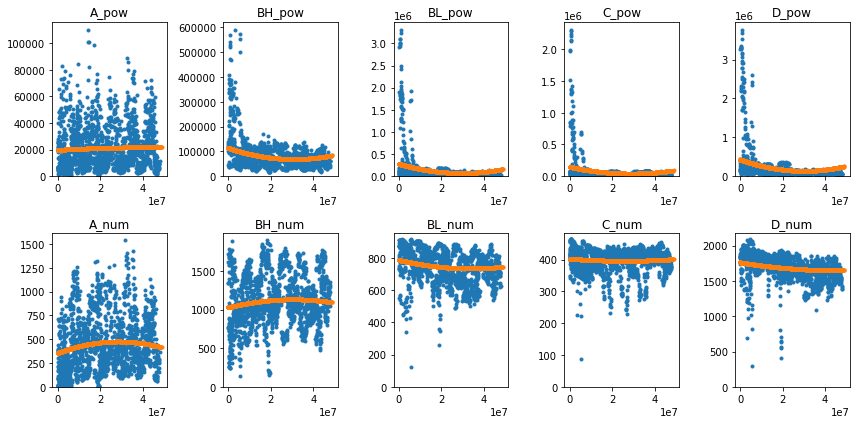

In [12]:
fig, ax = plt.subplots(2, 5, figsize = (12, 6))
x = train_set['time_to_eruption']
for i,type in enumerate(['A_pow','A_num','BH_pow','BH_num','BL_pow','BL_num','C_pow','C_num','D_pow','D_num']):
    y = np.zeros(len(x))
    for j in range(10):
        y += train_set[f's{j+1}_{type}']
    y /= 10
    x1 = np.polyfit(x, y.fillna(y.mean()), 2)
    y1 = np.poly1d(x1)(x)
    ax[i%2, i//2].plot(x, y,'.')
    ax[i%2, i//2].plot(x, y1,'.')
    ax[i%2, i//2].set_ylim(0,)
    ax[i%2, i//2].set_title(type)
fig.tight_layout()

# Modeling and Predicting

In [13]:
df = train_set.drop(['segment_id', 'time_to_eruption','h:m:s'], axis=1)
y = train_set['time_to_eruption']

X_train, X_val, y_train, y_val = train_test_split(df, y,
                                                  random_state = 42,
                                                  test_size = 0.2,
                                                  shuffle = True)

features = X_train.columns.tolist()
cat_features = {}

In [14]:
# lgb = LGBMRegressor(random_state = 42,
#                     max_depth = 7,
#                     n_estimators = 250,       ######### 
#                     learning_rate = 0.05)
# lgb.fit(X_train, y_train)
# preds = lgb.predict(X_val)

# print('RMSE: ', np.sqrt(mse(y_val, preds)))

In [15]:
def do_lgb(X_train, y_train, X_val, y_val):
    params = {'objective': 'rmse',
              'metric': 'rmse',
              'max_depth':14,
              'min_data_in_leaf':5,         # = min_child_samples
              'num_leaves': 2**7 - 1,
              'learning_rate': 0.05,
              'feature_fraction': 0.7,      # = colsample_bytree
              'bagging_fraction': 0.5,      # = subsample
              'bagging_freq': 5,
              'lambda_l1':80,               # = reg_alpha
              'num_iterations': 10000,      # = n_estimators
              'seed': 42,
              'verbose': 1
             }

    lgb_train = lgb.Dataset(X_train, y_train)
    lgb_eval = lgb.Dataset(X_val, y_val, reference=lgb_train)

    evals_result = {}
    model = lgb.train(
        params,
        lgb_train,
        valid_sets = (lgb_train, lgb_eval), 
        feature_name = features,
        categorical_feature = cat_features,
        verbose_eval = 100,
        evals_result = evals_result,
        early_stopping_rounds = 200)

    return model

In [16]:
lgb_model = do_lgb(X_train, y_train, X_val, y_val)

/opt/conda/lib/python3.7/site-packages/lightgbm/engine.py:148: UserWarning: Found `num_iterations` in params. Will use it instead of argument
  warnings.warn("Found `{}` in params. Will use it instead of argument".format(alias))
/opt/conda/lib/python3.7/site-packages/lightgbm/basic.py:1295: UserWarning: categorical_feature in Dataset is overridden.
New categorical_feature is []
  'New categorical_feature is {}'.format(sorted(list(categorical_feature))))


Training until validation scores don't improve for 200 rounds
[100]	training's rmse: 1.06852e+06	valid_1's rmse: 3.7067e+06
[200]	training's rmse: 527717	valid_1's rmse: 3.56862e+06
[300]	training's rmse: 313837	valid_1's rmse: 3.54617e+06
[400]	training's rmse: 203864	valid_1's rmse: 3.5378e+06
[500]	training's rmse: 157391	valid_1's rmse: 3.53367e+06
[600]	training's rmse: 133009	valid_1's rmse: 3.53151e+06
[700]	training's rmse: 123265	valid_1's rmse: 3.53038e+06
[800]	training's rmse: 80103.6	valid_1's rmse: 3.53039e+06
[900]	training's rmse: 41011	valid_1's rmse: 3.53185e+06
Early stopping, best iteration is:
[764]	training's rmse: 107377	valid_1's rmse: 3.52936e+06


# Predict test data

In [17]:
feature_df = make_features('test')
test_set = pd.merge(test, feature_df, on = 'segment_id')
test_set

,segment_id,time_to_eruption,s1_A_pow,s1_A_num,s1_BH_pow,s1_BH_num,s1_BL_pow,s1_BL_num,s1_C_pow,s1_C_num,s1_D_pow,s1_D_num,s2_A_pow,s2_A_num,s2_BH_pow,s2_BH_num,s2_BL_pow,s2_BL_num,s2_C_pow,s2_C_num,s2_D_pow,s2_D_num,s3_A_pow,s3_A_num,s3_BH_pow,s3_BH_num,s3_BL_pow,s3_BL_num,s3_C_pow,s3_C_num,s3_D_pow,s3_D_num,s4_A_pow,s4_A_num,s4_BH_pow,s4_BH_num,s4_BL_pow,s4_BL_num,s4_C_pow,s4_C_num,s4_D_pow,s4_D_num,s5_A_pow,s5_A_num,s5_BH_pow,s5_BH_num,s5_BL_pow,s5_BL_num,s5_C_pow,s5_C_num,s5_D_pow,s5_D_num,s6_A_pow,s6_A_num,s6_BH_pow,s6_BH_num,s6_BL_pow,s6_BL_num,s6_C_pow,s6_C_num,s6_D_pow,s6_D_num,s7_A_pow,s7_A_num,s7_BH_pow,s7_BH_num,s7_BL_pow,s7_BL_num,s7_C_pow,s7_C_num,s7_D_pow,s7_D_num,s8_A_pow,s8_A_num,s8_BH_pow,s8_BH_num,s8_BL_pow,s8_BL_num,s8_C_pow,s8_C_num,s8_D_pow,s8_D_num,s9_A_pow,s9_A_num,s9_BH_pow,s9_BH_num,s9_BL_pow,s9_BL_num,s9_C_pow,s9_C_num,s9_D_pow,s9_D_num,s10_A_pow,s10_A_num,s10_BH_pow,s10_BH_num,s10_BL_pow,s10_BL_num,s10_C_pow,s10_C_num,s10_D_pow,s10_D_num
0,1000213997,0,17.597704,1.0,8867.910844,383.0,84216.480896,906.0,40063.801367,457.0,129329.572247,2089.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.0,12329.686177,531.0,83743.579877,908.0,36067.137375,452.0,128066.484698,2112.0,19522.721302,565.0,94577.144264,1951.0,81090.084587,876.0,29721.826931,418.0,128884.834872,1947.0,6228.606164,343.0,92750.760999,2567.0,24539.714448,749.0,6120.665609,252.0,80090.280239,2034.0,400009.957563,3721.0,28547.950037,492.0,13343.525219,244.0,38922.803397,396.0,3196.984853,70.0,38109.956014,1150.0,7152.710971,335.0,19224.228968,613.0,56029.993579,462.0,27700.819001,1100.0,83645.216306,1504.0,144065.622154,2095.0,26926.538302,546.0,29066.869996,381.0,89336.719607,1658.0,2344.267813,89.0,38405.792485,1098.0,85617.674926,890.0,29999.525930,431.0,159993.577910,2142.0,0.000000,12220.0,0.000000,3290.0,0.000000,940.0,0.000000,470.0,0.000000,2350.0
1,100023368,0,84.145374,4.0,3288.538144,144.0,65479.224244,895.0,38721.344199,457.0,98388.166044,2020.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.0,8103.446900,363.0,54529.959940,890.0,34503.148680,451.0,92864.404037,2074.0,0.000000,0.0,68886.237507,1766.0,53345.784825,844.0,25864.208835,425.0,109242.327860,2017.0,8840.197574,454.0,66072.660922,2256.0,22301.080814,729.0,6440.216052,265.0,69723.938073,1933.0,4803.014790,127.0,2004.494271,55.0,26639.145520,529.0,87012.697593,458.0,10957.345086,281.0,41150.909812,1000.0,10581.007980,358.0,15757.552219,463.0,56271.150737,459.0,19085.847123,655.0,13295.427106,353.0,45306.877324,1223.0,13639.949086,373.0,52374.427127,445.0,13521.758923,420.0,18.259468,1.0,24206.073477,832.0,60432.819873,878.0,29015.140459,433.0,136848.722624,2146.0,0.000000,0.0,75226.889831,1254.0,98537.747734,865.0,51207.652288,437.0,235808.139324,2130.0
2,1000488999,0,25192.180094,1055.0,4050.298169,214.0,35901.306197,848.0,24588.850886,442.0,72748.339973,1949.0,55530.494518,949.0,229017.318766,2531.0,40649.329095,554.0,5974.050737,105.0,188498.680507,1855.0,0.000000,0.0,9682.905404,609.0,30396.672697,863.0,22501.453968,448.0,62481.368997,2062.0,143.539514,9.0,51506.966668,1855.0,35797.018409,833.0,19523.047731,427.0,75874.100422,2014.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26088.699784,571.0,6834.790632,168.0,32698.860737,677.0,73751.085411,464.0,21398.393886,624.0,67.549012,4.0,4836.946384,306.0,10050.032671,487.0,39637.178535,461.0,25124.555051,1161.0,11981.925556,364.0,29037.429567,1052.0,7219.561731,276.0,46037.005157,453.0,6099.475194,254.0,73.290916,4.0,24803.750055,1165.0,38339.819152,853.0,22353.247578,437.0,100755.037771,2167.0,0.000000,12220.0,0.000000,3290.0,0.000000,940.0,0.000000,470.0,0.000000,2350.0
3,1001028887,0,587.607721,29.0,8463.698327,400.0,52453.575382,882.0,44181.661922,457.0,100428.209756,2083.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.0,14619.295874,712.0,43255.561050,878.0,40211.330176,462.0,85067.405824,2074.0,92.274897,4.0,82615.962381,2141.0,51242.915826,871.0,25838.309010,435.0,97689.120339,2040.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN

In [18]:
# Predict test data
preds = lgb_model.predict(test_set.drop(['segment_id', 'time_to_eruption'], axis=1))
test['time_to_eruption'] = preds
result=test[['segment_id','time_to_eruption']]
result['h:m:s']=(result['time_to_eruption'].apply(lambda x:datetime.timedelta(seconds = x/100)))
result


,segment_id,time_to_eruption,h:m:s
0,1000213997,2.161576e+07,2 days 12:02:37.564131
1,100023368,3.949369e+07,4 days 13:42:16.861700
2,1000488999,2.118988e+07,2 days 10:51:38.847135
3,1001028887,2.670298e+07,3 days 02:10:29.778545
4,1001857862,1.431767e+07,1 days 15:46:16.680904
...,...,...,...
4515,996704281,2.537069e+07,2 days 22:28:26.857097
4516,997630809,1.703141e+07,1 days 23:18:34.061603
4517,998072137,2.198896e+07,2 days 13:04:49.583031
4518,998136924,3.814652e+07,4 days 09:57:45.244150


In [19]:
test[['segment_id','time_to_eruption']].to_csv('submission.csv', index=False)